In [33]:
import numpy as np
import config
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from scipy.stats import kruskal

from get_data import DataLoader

# Load data
DataLoader = DataLoader(config.DATA_PATH)
df = DataLoader.load_data()
df_reg = df[df['year']==2020].copy()
df_reg = df_reg[['who_region', 'pm10_concentration']].dropna()

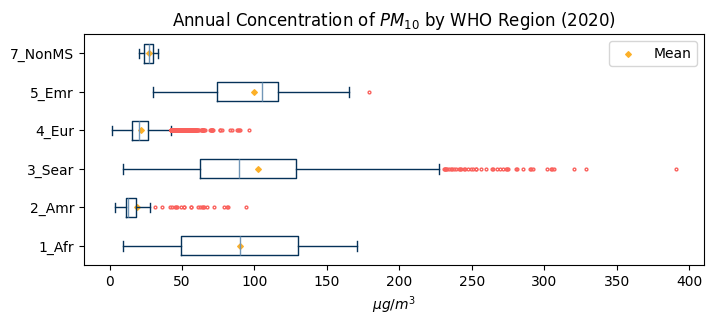

In [46]:
regions = sorted(df['who_region'].unique())

data_by_region = [df[df['who_region'] == region]['pm10_concentration'].dropna() for region in regions]
means_by_region = [region.mean() for region in data_by_region]
y_positions = np.arange(1, len(regions) + 1)

plt.figure(figsize=(8, 3))
plt.boxplot(
    data_by_region,
    vert=False,
    tick_labels=regions,
    boxprops=dict(color='#053259'),
    whiskerprops=dict(color='#053259'),
    capprops=dict(color='#053259'),
    medianprops=dict(color='#7196B7'),
    flierprops=dict(marker='o', markeredgecolor='#FA615C', markersize=2)
)
plt.scatter(means_by_region, y_positions, marker='D', color='#FCB028', s=8, label=f'Mean')
plt.title('Annual Concentration of $PM_{10}$ by WHO Region (2020)')
plt.xlabel('$µg/m^3$')
# plt.xscale('log')
plt.legend()

plt.savefig('q4_box_pm10_region.png', dpi=300, bbox_inches='tight')
plt.show()

In [37]:

statistic, p_value = kruskal(*data_by_region)
print(f"Kruskal-Wallis test result: {statistic}, p-value={p_value:.6e}")

Kruskal-Wallis test result: 3421.649420460773, p-value=0.000000e+00
